# Customer Churn Prediction & Analysis

**Project Overview**

Customer churn is an important business problem for telecom companies because
retaining existing customers can be more cost-effective than acquiring new ones.

In this project, machine learning techniques are used to predict customer churn
and identify customer characteristics associated with churn risk.

The project covers:

- Data cleaning and preprocessing
- Exploratory data analysis
- Classification model development
- Hyperparameter tuning
- Model evaluation
- Model interpretation
- Business insights

## 1. Data Understanding & Cleaning

In [1]:
import pandas as pd 
import numpy as np 

df = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")

### 1.1.Checking missing values and data types

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [3]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

### 1.2. Missing Value Analysis

Almost all variables contain no missing values. Churn Reason contains
5,174 missing values because this information is only available for
customers who churned.

Churn Reason will be excluded from the machine learning features because
it is known only after churn occurs and would cause data leakage.

Dropping Columns

In [4]:
drop_cols = [
    "CustomerID",
    "Churn Reason",
    "Churn Value",
    "Churn Score",
    "CLTV",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude"
]

df_model = df.drop(columns = drop_cols)

In [5]:
df_model.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label'],
      dtype='str')

In [6]:
df_model["Total Charges"] = df_model["Total Charges"].fillna(0)

In [7]:
df_model["Total Charges"].isnull().sum()

np.int64(0)

### 1.3. Total Charges Data Type Conversion

In [8]:
df_model["Total Charges"] = pd.to_numeric(
    df_model["Total Charges"], 
    errors = "coerce"
)

### 1.4.Investigating CLTV

In [9]:
df[["CLTV", "Churn Label", "Churn Value", "Tenure Months"]].head(10)

,CLTV,Churn Label,Churn Value,Tenure Months
0,3239,Yes,1,2
1,2701,Yes,1,2
2,5372,Yes,1,8
3,5003,Yes,1,28
4,5340,Yes,1,49
5,5925,Yes,1,10
6,5433,Yes,1,1
7,4832,Yes,1,1
8,5789,Yes,1,47
9,2915,Yes,1,1


In [10]:
df.groupby("Churn Label")["CLTV"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
Churn Label,,,,,
No,5174,4490.92,4620.0,2003,6500
Yes,1869,4149.41,4238.0,2003,6484


In [11]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

Further investigation in section 7.5.

## 2. Feature Preparation

In [12]:
from sklearn.model_selection import train_test_split

# Separate the input features from the target variable
X = df_model.drop(columns=["Churn Label"])
y = df_model["Churn Label"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (7043, 19)
Target shape: (7043,)


### 2.1. Train and Test Split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


### 2.2. Separating Numerical and Categorical Columns

In [14]:
# Identify categorical features
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Identify numerical features
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))
print("Total features:", len(categorical_cols) + len(numerical_cols))

Categorical features: 16
Numerical features: 3
Total features: 19


## 3. Data Preprocessing

In [15]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

#### 3.1. Combined Preprocessor

In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_cols
        )
    ]
)


In [17]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (5634, 46)
Processed test shape: (1409, 46)


| Feature type | What we do     | Why                                            |
| ------------ | -------------- | ---------------------------------------------- |
| Categorical  | One-hot encode | Converts categories into numerical columns     |
| Numerical    | StandardScaler | Puts numerical variables on a comparable scale |


## 4. Baseline Models

### 4.1 Logistic Regression

Logistic Regression was used as a baseline linear classification model for predicting customer churn.

In [18]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

Earlier we checked missing values in the original dataset and found Churn Reason missing, which we intentionally removed.

But after converting any values that couldn't be converted became NaN.

In [19]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape)
print(X_test_processed.shape)

(5634, 46)
(1409, 46)


#### Train the model

In [20]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

#### Make predictions

In [21]:
y_pred = log_model.predict(X_test_processed)

y_pred[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No'],
      dtype=object)

#### Get churn probabilities

In [22]:
y_proba = log_model.predict_proba(X_test_processed)

y_proba[:10]

array([[0.92417784, 0.07582216],
       [0.32707517, 0.67292483],
       [0.89883744, 0.10116256],
       [0.52404094, 0.47595906],
       [0.96883064, 0.03116936],
       [0.37834673, 0.62165327],
       [0.53256542, 0.46743458],
       [0.95847074, 0.04152926],
       [0.99888142, 0.00111858],
       [0.61273225, 0.38726775]])

The first column is probability of No, and the second column is probability of Yes.

#### Now we evaluate the model

In [23]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8019872249822569


#### Confusion Matrix

In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[917 118]
 [161 213]]


|                | **Predicted No** | **Predicted Yes** |
| -------------- | ---------------: | ----------------: |
| **Actual No**  |          **917** |           **118** |
| **Actual Yes** |          **161** |           **213** |

The model correctly identified 917 customers who did not churn.

The model incorrectly flagged 118 customers as likely to churn. 
Think of this as a false alarm.

**The model missed 161 customers who actually churned. This is particularly important in a churn problem because these are customers the model failed to identify as churn risks.**

The model correctly identified 214 customers who actually churned.

What percentage of actual churners did our model successfully identify?

In [25]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred, pos_label="Yes")

print("Recall:", recall)

Recall: 0.56951871657754


#### Precision

Precision answers:

Of all the customers our model predicted would churn, how many actually churned?

In [26]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred, pos_label="Yes")

print("Precision:", precision)

Precision: 0.6435045317220544


#### F1-score

We can combine precision and recall into a single metric called the F1-score:
 
It gives a balance between precision and recall.

In [27]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("F1 Score:", f1)

F1 Score: 0.6042553191489362


| Metric        |     Result | What it tells us                         |
| ------------- | ---------: | ---------------------------------------- |
| **Accuracy**  | **80.19%** | Overall correct predictions              |
| **Precision** | **64.35%** | When predicting churn, how often correct |
| **Recall**    | **56.95%** | Actual churners successfully detected    |
| **F1-score**  | **60.42%** | Balance of precision and recall          |


#### Classification Report

Rather than calculating each metric separately, sklearn can give us the complete report in one place.

In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



### 4.2 Decision Tree

In [29]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [30]:
y_pred_tree = tree_model.predict(X_test_processed)

y_pred_tree[:10]

array(['No', 'No', 'No', 'Yes', 'No', 'No', 'Yes', 'Yes', 'No', 'Yes'],
      dtype=object)

In [31]:
from sklearn.metrics import accuracy_score

accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", accuracy_tree)

Decision Tree Accuracy: 0.7423704755145494


In [32]:
from sklearn.metrics import confusion_matrix

cm_tree = confusion_matrix(y_test, y_pred_tree)

print(cm_tree)

[[840 195]
 [168 206]]


In [33]:
from sklearn.metrics import recall_score

recall_tree = recall_score(
    y_test,
    y_pred_tree,
    pos_label="Yes"
)

print("Decision Tree Recall:", recall_tree)

Decision Tree Recall: 0.5508021390374331


In [34]:
from sklearn.metrics import precision_score

precision_tree = precision_score(
    y_test,
    y_pred_tree,
    pos_label="Yes"
)

print("Decision Tree Precision:", precision_tree)

Decision Tree Precision: 0.513715710723192


In [35]:
from sklearn.metrics import f1_score

f1_tree = f1_score(
    y_test,
    y_pred_tree,
    pos_label="Yes"
)

print("Decision Tree F1 Score:", f1_tree)

Decision Tree F1 Score: 0.5316129032258065


In [36]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

          No       0.83      0.81      0.82      1035
         Yes       0.51      0.55      0.53       374

    accuracy                           0.74      1409
   macro avg       0.67      0.68      0.68      1409
weighted avg       0.75      0.74      0.75      1409



### 4.3 Random Forest

A Random Forest is essentially an ensemble of many Decision Trees. Instead of relying on one tree, it builds multiple trees and combines their predictions.

In [37]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [38]:
rf_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [39]:
y_pred_rf = rf_model.predict(X_test_processed)

y_pred_rf[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No'],
      dtype=object)

In [40]:
from sklearn.metrics import accuracy_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.7934705464868701


In [41]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[920 115]
 [176 198]]


In [42]:
from sklearn.metrics import recall_score

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

print("Random Forest Recall:", recall_rf)

Random Forest Recall: 0.5294117647058824


In [43]:
from sklearn.metrics import precision_score

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

print("Random Forest Precision:", precision_rf)

Random Forest Precision: 0.6325878594249201


In [44]:
from sklearn.metrics import f1_score

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

print("Random Forest F1 Score:", f1_rf)

Random Forest F1 Score: 0.5764192139737991


In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

          No       0.84      0.89      0.86      1035
         Yes       0.63      0.53      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



## 5. Hyperparameter Tuning

### 5.1. Decision Tree

Hyperparameter tuning = trying different settings to find a model configuration that generalizes well to unseen data.

max_depth = Controls the maximum depth of the tree.

min_samples_split = Minimum number of observations required before a node can be split.

In [46]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

f1_yes = make_scorer(
    f1_score,
    pos_label="Yes"
)

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

tree_param_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5]
}

grid_tree_pipeline = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_tree_pipeline.fit(X_train, y_train)

print("Best Parameters:", grid_tree_pipeline.best_params_)
print("Best CV F1:", grid_tree_pipeline.best_score_)


Best Parameters: {'model__max_depth': 7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best CV F1: 0.5824623974815714


In [47]:
grid_search_tree = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_search_tree.fit(X_train, y_train)

print("Best parameters:", grid_search_tree.best_params_)
print("Best cross-validation F1:", grid_search_tree.best_score_)

Best parameters: {'model__max_depth': 7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best cross-validation F1: 0.5824623974815714


In [48]:
print("Best Parameters:", grid_search_tree.best_params_)
print("Best Cross-Validation F1:", grid_search_tree.best_score_)

Best Parameters: {'model__max_depth': 7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best Cross-Validation F1: 0.5824623974815714


In [49]:
best_tree = grid_search_tree.best_estimator_

y_pred_tree_tuned = best_tree.predict(X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred_tree_tuned))
print("Precision:", precision_score(y_test, y_pred_tree_tuned, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_pred_tree_tuned, pos_label="Yes"))
print("F1 Score:", f1_score(y_test, y_pred_tree_tuned, pos_label="Yes"))

Accuracy: 0.78708303761533
Precision: 0.6149068322981367
Recall: 0.5294117647058824
F1 Score: 0.5689655172413793


So tuning substantially improved the Decision Tree.

The particularly important improvement is precision: the original tree's churn predictions were correct about 48% of the time, while the tuned tree's were correct about 60% of the time.

#### Pipeline Creation

Ideally, preprocessing should happen inside a Pipeline, so each cross-validation fold learns its own scaling/encoding parameters.

In [50]:
from sklearn.pipeline import Pipeline

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

param_grid_pipeline = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5]
}

grid_tree_pipeline = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid_pipeline,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_tree_pipeline.fit(X_train, y_train)

print("Best Parameters:", grid_tree_pipeline.best_params_)
print("Best CV F1:", grid_tree_pipeline.best_score_)

Best Parameters: {'model__max_depth': 7, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2}
Best CV F1: 0.5824623974815714


In [51]:
y_pred_tree_pipeline = grid_tree_pipeline.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_tree_pipeline))
print("Precision:", precision_score(
    y_test,
    y_pred_tree_pipeline,
    pos_label="Yes"
))
print("Recall:", recall_score(
    y_test,
    y_pred_tree_pipeline,
    pos_label="Yes"
))
print("F1 Score:", f1_score(
    y_test,
    y_pred_tree_pipeline,
    pos_label="Yes"
))

Accuracy: 0.78708303761533
Precision: 0.6149068322981367
Recall: 0.5294117647058824
F1 Score: 0.5689655172413793


### 5.2. Logistic Regression

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

log_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

grid_log = GridSearchCV(
    estimator=log_pipeline,
    param_grid=log_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_log.fit(X_train, y_train)

print("Best Parameters:", grid_log.best_params_)
print("Best CV F1:", grid_log.best_score_)

Best Parameters: {'model__C': 10, 'model__class_weight': 'balanced'}
Best CV F1: 0.6429973056205254


In [53]:
y_pred_log_tuned = grid_log.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_log_tuned))

print("Precision:", precision_score(
    y_test,
    y_pred_log_tuned,
    pos_label="Yes"
))

print("Recall:", recall_score(
    y_test,
    y_pred_log_tuned,
    pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test,
    y_pred_log_tuned,
    pos_label="Yes"
))

Accuracy: 0.7430801987224982
Precision: 0.5104529616724739
Recall: 0.7834224598930482
F1 Score: 0.6181434599156118


### 5.3. Random Forest

In [54]:
# Create training and test datasets without CLTV
X_train_no_cltv = X_train.drop(columns=["CLTV"], errors="ignore").copy()
X_test_no_cltv = X_test.drop(columns=["CLTV"], errors="ignore").copy()

# Convert churn labels to binary: Yes = 1, No = 0
y_train_binary = (y_train == "Yes").astype(int)

print("Training features:", X_train_no_cltv.shape)
print("Test features:", X_test_no_cltv.shape)
print("CLTV included:", "CLTV" in X_train_no_cltv.columns)

Training features: (5634, 19)
Test features: (1409, 19)
CLTV included: False


In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_no_cltv = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_cols)
])

rf_no_cltv = Pipeline([
    ("preprocessor", preprocessor_no_cltv),
    ("model", RandomForestClassifier(
        random_state=42,
        n_estimators=200,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced"
    ))
])

In [56]:
rf_no_cltv.fit(X_train_no_cltv, y_train_binary)

best_rf_model = rf_no_cltv

print("Random Forest without CLTV is trained.")

Random Forest without CLTV is trained.


In [57]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__class_weight": [None, "balanced"]
}

grid_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best CV F1:", grid_rf.best_score_)

Best Parameters: {'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV F1: 0.6454293467926865


In [58]:
y_pred_rf_tuned = grid_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))

print("Precision:", precision_score(
    y_test,
    y_pred_rf_tuned,
    pos_label="Yes"
))

print("Recall:", recall_score(
    y_test,
    y_pred_rf_tuned,
    pos_label="Yes"
))

print("F1 Score:", f1_score(
    y_test,
    y_pred_rf_tuned,
    pos_label="Yes"
))

Accuracy: 0.758694109297374
Precision: 0.5318352059925093
Recall: 0.7593582887700535
F1 Score: 0.6255506607929515


## 6. Additional Machine Learning Models

### 6.1. KNN

In [59]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV


knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Best Parameters:", grid_knn.best_params_)
print("Best CV F1:", grid_knn.best_score_)


Best Parameters: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}
Best CV F1: 0.6133143811055426


In [60]:
y_pred_knn = grid_knn.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, pos_label="Yes")
recall_knn = recall_score(y_test, y_pred_knn, pos_label="Yes")
f1_knn = f1_score(y_test, y_pred_knn, pos_label="Yes")

print("Accuracy:", accuracy_knn)
print("Precision:", precision_knn)
print("Recall:", recall_knn)
print("F1 Score:", f1_knn)

Accuracy: 0.7842441447835344
Precision: 0.5956284153005464
Recall: 0.5828877005347594
F1 Score: 0.5891891891891892


In [61]:
cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=["No", "Yes"]
)

print(cm_knn)

[[887 148]
 [156 218]]


In [62]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

          No       0.85      0.86      0.85      1035
         Yes       0.60      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409



- Its accuracy is 78.71%, slightly higher than all three tuned models.

- Its precision is 59.89%, close to the tuned Decision Tree.

- Its recall is 59.89%, substantially lower than tuned Logistic Regression and Random Forest.

- Its F1 = 59.89%, so it doesn't surpass the current Random Forest on this metric.

### 6.2. Support Vector Machine (SVM)

In [63]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(
        probability=True,
        random_state=42
    ))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", "auto"]
}

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Best Parameters:", grid_svm.best_params_)
print("Best CV F1:", grid_svm.best_score_)

c:\Users\markr\Desktop\Git\customer-churn-prediction\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best Parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best CV F1: 0.6096488829111183


In [64]:
y_pred_svm = grid_svm.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, pos_label="Yes")
recall_svm = recall_score(y_test, y_pred_svm, pos_label="Yes")
f1_svm = f1_score(y_test, y_pred_svm, pos_label="Yes")

print("Accuracy:", accuracy_svm)
print("Precision:", precision_svm)
print("Recall:", recall_svm)
print("F1 Score:", f1_svm)

Accuracy: 0.7998580553584103
Precision: 0.6428571428571429
Recall: 0.553475935828877
F1 Score: 0.5948275862068966


In [65]:
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=["No", "Yes"]
)

print(cm_svm)

[[920 115]
 [167 207]]


In [66]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



### 6.3. AdaBoost

In [67]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

ada_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", AdaBoostClassifier(
        random_state=42
    ))
])

ada_param_grid = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.01, 0.1, 1.0]
}

grid_ada = GridSearchCV(
    estimator=ada_pipeline,
    param_grid=ada_param_grid,
    cv=5,
    scoring=f1_yes,
    n_jobs=-1
)

grid_ada.fit(X_train, y_train)

print("Best Parameters:", grid_ada.best_params_)
print("Best CV F1:", grid_ada.best_score_)

Best Parameters: {'model__learning_rate': 1.0, 'model__n_estimators': 200}
Best CV F1: 0.6125010117429783


In [68]:
y_pred_ada = grid_ada.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_ada = accuracy_score(y_test, y_pred_ada)
precision_ada = precision_score(y_test, y_pred_ada, pos_label="Yes")
recall_ada = recall_score(y_test, y_pred_ada, pos_label="Yes")
f1_ada = f1_score(y_test, y_pred_ada, pos_label="Yes")

print("Accuracy:", accuracy_ada)
print("Precision:", precision_ada)
print("Recall:", recall_ada)
print("F1 Score:", f1_ada)

Accuracy: 0.8034066713981547
Precision: 0.6430678466076696
Recall: 0.5828877005347594
F1 Score: 0.6115007012622721


In [69]:
cm_ada = confusion_matrix(
    y_test,
    y_pred_ada,
    labels=["No", "Yes"]
)

print(cm_ada)

[[914 121]
 [156 218]]


In [70]:
print(classification_report(y_test, y_pred_ada))

              precision    recall  f1-score   support

          No       0.85      0.88      0.87      1035
         Yes       0.64      0.58      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



### 6.4. XGBoost

In [71]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [72]:
y_train_binary = (y_train == "Yes").astype(int)
y_test_binary = (y_test == "Yes").astype(int)

print(y_train_binary.value_counts())
print(y_test_binary.value_counts())

Churn Label
0    4139
1    1495
Name: count, dtype: int64
Churn Label
0    1035
1     374
Name: count, dtype: int64


In [73]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

f1_binary = make_scorer(
    f1_score,
    pos_label=1
)

xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring=f1_binary,
    n_jobs=-1
)

grid_xgb.fit(X_train, y_train_binary)

print("Best Parameters:", grid_xgb.best_params_)
print("Best CV F1:", grid_xgb.best_score_)

Best Parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 1.0}
Best CV F1: 0.6165090068555064


In [74]:
y_proba_xgb = grid_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = (y_proba_xgb >= 0.5).astype(int)
y_test_binary = (y_test == "Yes").astype(int)

print("Accuracy:", accuracy_score(y_test_binary, y_pred_xgb))
print("Precision:", precision_score(y_test_binary, y_pred_xgb))
print("Recall:", recall_score(y_test_binary, y_pred_xgb))
print("F1 Score:", f1_score(y_test_binary, y_pred_xgb))

Accuracy: 0.8069552874378992
Precision: 0.660377358490566
Recall: 0.5614973262032086
F1 Score: 0.6069364161849711


In [75]:
cm_xgb = confusion_matrix(
    y_test_binary,
    y_pred_xgb
)

print(cm_xgb)

[[927 108]
 [164 210]]


In [76]:
print(
    classification_report(
        y_test_binary,
        y_pred_xgb
    )
)

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [77]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Get churn probabilities
y_proba_rf = grid_rf.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.30, 0.65, 0.05)

rows = []

for threshold in thresholds:

    # Convert probability into Yes/No prediction
    y_pred_threshold = np.where(
        y_proba_rf >= threshold,
        "Yes",
        "No"
    )

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=["No", "Yes"]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "F1": f1_score(
            y_test,
            y_pred_threshold,
            pos_label="Yes"
        ),
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(rows)

print(threshold_df)

   Threshold  Precision    Recall        F1   FP   FN
0       0.30   0.451138  0.901070  0.601249  410   37
1       0.35   0.469914  0.877005  0.611940  370   46
2       0.40   0.496933  0.866310  0.631579  328   50
3       0.45   0.516129  0.812834  0.631360  285   70
4       0.50   0.531835  0.759358  0.625551  250   90
5       0.55   0.554639  0.719251  0.626310  216  105
6       0.60   0.578947  0.676471  0.623921  184  121


In [78]:
y_proba_xgb = grid_xgb.best_estimator_.predict_proba(X_test)[:, 1]

y_pred_xgb = np.where(
    y_proba_xgb >= 0.50,
    "Yes",
    "No"
)

print("XGBoost Test Results")
print("Precision:", precision_score(y_test, y_pred_xgb, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_pred_xgb, pos_label="Yes"))
print("F1 Score:", f1_score(y_test, y_pred_xgb, pos_label="Yes"))

XGBoost Test Results
Precision: 0.660377358490566
Recall: 0.5614973262032086
F1 Score: 0.6069364161849711


## 7. Model Evaluation


### 7.1. Repeated Cross-Validation

In [79]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

y_train_bin = (y_train == "Yes").astype(int)
y_test_bin = (y_test == "Yes").astype(int).values


def no_cltv_version(tuned_pipeline):
    tuned_model = tuned_pipeline.steps[-1][1]
    return Pipeline([
        ("preprocessor", clone(preprocessor_no_cltv)),
        ("model", clone(tuned_model)),
    ])


tuned = {
    "Logistic Regression": grid_log.best_estimator_,
    "Decision Tree": grid_tree_pipeline.best_estimator_,
    "KNN": grid_knn.best_estimator_,
    "SVM": grid_svm.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "AdaBoost": grid_ada.best_estimator_,
    "XGBoost": grid_xgb.best_estimator_,
}
models_no_cltv = {name: no_cltv_version(m) for name, m in tuned.items()}

repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "precision": "precision",
    "recall": "recall",
}

cv_rows = []
for name, model in models_no_cltv.items():
    s = cross_validate(model, X_train, y_train_bin, cv=repeated_cv,
                       scoring=scoring, n_jobs=-1, error_score="raise")
    cv_rows.append({
        "Model": name,
        "PR-AUC mean": s["test_pr_auc"].mean(),
        "PR-AUC sd": s["test_pr_auc"].std(),
        "ROC-AUC mean": s["test_roc_auc"].mean(),
        "ROC-AUC sd": s["test_roc_auc"].std(),
        "F1 @ default": s["test_f1"].mean(),
        "Precision @ default": s["test_precision"].mean(),
        "Recall @ default": s["test_recall"].mean(),
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("PR-AUC mean", ascending=False)

best_idx = cv_results_df["PR-AUC mean"].idxmax()
best_mean = cv_results_df.loc[best_idx, "PR-AUC mean"]
best_sd = cv_results_df.loc[best_idx, "PR-AUC sd"]
cv_results_df["Within 1 SD of best (PR-AUC)"] = cv_results_df["PR-AUC mean"] >= best_mean - best_sd

cv_results_df.round(4).reset_index(drop=True)

,Model,PR-AUC mean,PR-AUC sd,ROC-AUC mean,ROC-AUC sd,F1 @ default,Precision @ default,Recall @ default,Within 1 SD of best (PR-AUC)
0,XGBoost,0.6909,0.0172,0.8642,0.0103,0.6115,0.6747,0.5599,True
1,AdaBoost,0.6830,0.0164,0.8612,0.0104,0.6160,0.6644,0.5755,True
2,Logistic Regression,0.6790,0.0181,0.8591,0.0101,0.6418,0.5306,0.8125,True
3,Random Forest,0.6781,0.0176,0.8609,0.0096,0.6458,0.5529,0.7770,True
4,SVM,0.6732,0.0160,0.8520,0.0104,0.6058,0.6637,0.5581,False
5,KNN,0.6056,0.0207,0.8353,0.0105,0.6094,0.6123,0.6076,False
6,Decision Tree,0.6003,0.0193,0.8274,0.0125,0.5871,0.6129,0.5661,False


**Repeated Cross-Validation Findings**

Seven tuned models were compared using 5-fold stratified cross-validation repeated three times on the training set, with identical preprocessing and CLTV excluded. Models were ranked on threshold-free metrics. XGBoost (PR-AUC 0.691 ± 0.017), AdaBoost (0.683), Logistic Regression (0.679) and Random Forest (0.678) were hard to distinguish, with differences smaller than fold-to-fold variation. SVM (0.673) was marginally behind, and KNN (0.606) and the Decision Tree (0.600) were clearly weaker. F1 at the default cutoff mainly reflects each model’s precision-recall trade-off (for example, Logistic Regression recall 0.81 vs XGBoost 0.56), so it is not used to rank models.

### 7.2. Final 7-model comparison

In [80]:
fitted_models, test_scores = {}, {}      
test_rows = []

for name, model in models_no_cltv.items():
    fitted = clone(model).fit(X_train, y_train_bin)

    names = fitted.named_steps["preprocessor"].get_feature_names_out()
    assert not any("CLTV" in n for n in names), f"{name} still uses CLTV"

    pred = fitted.predict(X_test)
    if hasattr(fitted, "predict_proba"):
        score = fitted.predict_proba(X_test)[:, 1]
    else:
        score = fitted.decision_function(X_test)

    fitted_models[name] = fitted         
    test_scores[name] = score            

    test_rows.append({
        "Model": name,
        "Accuracy": (pred == y_test_bin).mean(),
        "Precision": precision_score(y_test_bin, pred, zero_division=0),
        "Recall": recall_score(y_test_bin, pred),
        "F1": f1_score(y_test_bin, pred),
        "ROC-AUC": roc_auc_score(y_test_bin, score),
        "PR-AUC": average_precision_score(y_test_bin, score),
    })

test_results_df = pd.DataFrame(test_rows).sort_values("PR-AUC", ascending=False)
test_results_df.round(4).reset_index(drop=True)

c:\Users\markr\Desktop\Git\customer-churn-prediction\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,AdaBoost,0.8034,0.6431,0.5829,0.6115,0.8526,0.6723
1,XGBoost,0.8070,0.6604,0.5615,0.6069,0.8549,0.6713
2,Random Forest,0.7587,0.5318,0.7594,0.6256,0.8490,0.6607
3,Logistic Regression,0.7431,0.5105,0.7834,0.6181,0.8480,0.6421
4,SVM,0.7999,0.6429,0.5535,0.5948,0.8375,0.6294
5,Decision Tree,0.7871,0.6149,0.5294,0.5690,0.8271,0.6164
6,KNN,0.7842,0.5956,0.5829,0.5892,0.8267,0.6044


Models were also evaluated once on the held-out test set at their default cutoffs. This table is descriptive, as model choice was based on cross-validation. AdaBoost (PR-AUC 0.672), XGBoost (0.671) and Random Forest (0.661) led, and the Decision Tree (0.616) and KNN (0.604) were weakest. Test PR-AUC was generally somewhat below the CV mean, consistent with sampling variation given 374 churners in the test set. Accuracy (0.743 to 0.807) is not informative, since always predicting no churn gives about 0.735.

### 7.3. ROC-AUC & PR-AUC

In [81]:
y_proba_log = test_scores["Logistic Regression"]
y_proba_tree = test_scores["Decision Tree"]
y_proba_knn = test_scores["KNN"]
y_proba_svm = test_scores["SVM"]
y_proba_rf = test_scores["Random Forest"]
y_proba_ada = test_scores["AdaBoost"]
y_proba_xgb = test_scores["XGBoost"]

from sklearn.metrics import roc_auc_score

for label, p in [("Logistic Regression", y_proba_log), ("KNN", y_proba_knn),
                 ("SVM", y_proba_svm), ("Decision Tree", y_proba_tree),
                 ("Random Forest", y_proba_rf), ("AdaBoost", y_proba_ada),
                 ("XGBoost", y_proba_xgb)]:
    print(f"{label}: {roc_auc_score(y_test_bin, p):.4f}")

# If a later cell in 7.2/7.3 refers to auc_log, auc_rf, etc., add:
auc_log = roc_auc_score(y_test_bin, y_proba_log)
auc_knn = roc_auc_score(y_test_bin, y_proba_knn)
auc_svm = roc_auc_score(y_test_bin, y_proba_svm)
auc_tree = roc_auc_score(y_test_bin, y_proba_tree)
auc_rf = roc_auc_score(y_test_bin, y_proba_rf)
auc_ada = roc_auc_score(y_test_bin, y_proba_ada)
auc_xgb = roc_auc_score(y_test_bin, y_proba_xgb)

Logistic Regression: 0.8480
KNN: 0.8267
SVM: 0.8375
Decision Tree: 0.8271
Random Forest: 0.8490
AdaBoost: 0.8526
XGBoost: 0.8549


In [82]:
from sklearn.metrics import average_precision_score

pr_log = average_precision_score(y_test_binary, y_proba_log)
pr_knn = average_precision_score(y_test_binary, y_proba_knn)
pr_svm = average_precision_score(y_test_binary, y_proba_svm)
pr_tree = average_precision_score(y_test_binary, y_proba_tree)
pr_rf = average_precision_score(y_test_binary, y_proba_rf)
pr_ada = average_precision_score(y_test_binary, y_proba_ada)
pr_xgb = average_precision_score(y_test_binary, y_proba_xgb)

print("Logistic Regression:", pr_log)
print("KNN:", pr_knn)
print("SVM:", pr_svm)
print("Decision Tree:", pr_tree)
print("Random Forest:", pr_rf)
print("AdaBoost:", pr_ada)
print("XGBoost:", pr_xgb)

Logistic Regression: 0.6420678757019009
KNN: 0.604397106479481
SVM: 0.6293521055503044
Decision Tree: 0.616423278934925
Random Forest: 0.6606622505484477
AdaBoost: 0.672337208135957
XGBoost: 0.6713069314203535


In [83]:
auc_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost"
    ],
    "ROC-AUC": [
        auc_log,
        auc_knn,
        auc_svm,
        auc_tree,
        auc_rf,
        auc_ada,
        auc_xgb
    ],
    "PR-AUC": [
        pr_log,
        pr_knn,
        pr_svm,
        pr_tree,
        pr_rf,
        pr_ada,
        pr_xgb
    ]
})

print(auc_results)

                 Model   ROC-AUC    PR-AUC
0  Logistic Regression  0.848048  0.642068
1                  KNN  0.826704  0.604397
2                  SVM  0.837467  0.629352
3        Decision Tree  0.827102  0.616423
4        Random Forest  0.848960  0.660662
5             AdaBoost  0.852599  0.672337
6              XGBoost  0.854871  0.671307


### 7.4. ROC Curve

In [84]:
from sklearn.metrics import roc_curve

fpr_log, tpr_log, _ = roc_curve(
    y_test_binary,
    y_proba_log
)

fpr_knn, tpr_knn, _ = roc_curve(
    y_test_binary,
    y_proba_knn
)

fpr_svm, tpr_svm, _ = roc_curve(
    y_test_binary,
    y_proba_svm
)

fpr_tree, tpr_tree, _ = roc_curve(
    y_test_binary,
    y_proba_tree
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test_binary,
    y_proba_rf
)

fpr_ada, tpr_ada, _ = roc_curve(
    y_test_binary,
    y_proba_ada
)

fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test_binary,
    y_proba_xgb
)

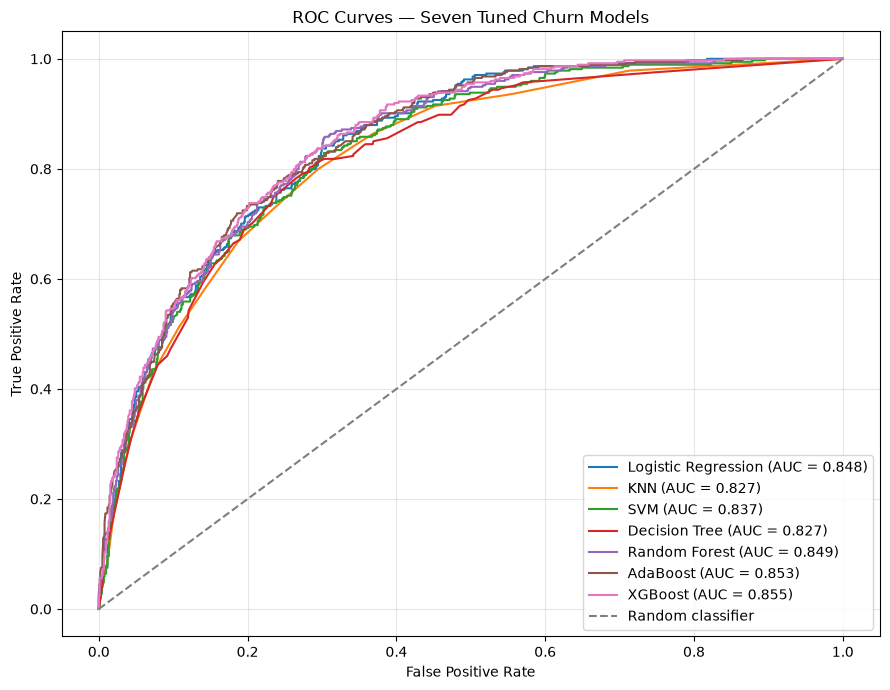

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.3f})"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN (AUC = {auc_knn:.3f})"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"SVM (AUC = {auc_svm:.3f})"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree (AUC = {auc_tree:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_ada,
    tpr_ada,
    label=f"AdaBoost (AUC = {auc_ada:.3f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Seven Tuned Churn Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.5. Testing RF with CLTV

**CLTV Feature Investigation**

Random Forest was evaluated using repeated stratified 5-fold cross-validation, repeated three times, with and without Customer Lifetime Value (CLTV). Removing CLTV reduced mean F1 from 0.6514 to 0.6464 and mean ROC-AUC from 0.8618 to 0.8610. These small changes suggest that CLTV provides limited additional predictive value under the current model settings. Since the exact timing and inputs of the CLTV calculation have not been established, this comparison does not confirm or rule out data leakage. Excluding CLTV is a reasonable conservative choice until its availability at prediction time can be verified.

In [86]:
X_train_no_cltv = X_train.copy()
X_test_no_cltv = X_test.copy()

In [87]:

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_cols_no_cltv = [
    col for col in numerical_cols if col != "CLTV"
]

preprocessor_no_cltv = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_cols_no_cltv
        )
    ]
)

rf_no_cltv = Pipeline([
    ("preprocessor", preprocessor_no_cltv),
    ("model", grid_rf.best_estimator_.named_steps["model"])
])

scores_no_cltv = cross_validate(
    rf_no_cltv,
    X_train_no_cltv,
    y_train_binary,
    cv=repeated_cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest WITHOUT CLTV")
print("Mean F1:", round(scores_no_cltv["test_f1"].mean(), 4))
print("F1 Std:", round(scores_no_cltv["test_f1"].std(), 4))
print("Mean ROC-AUC:", round(scores_no_cltv["test_roc_auc"].mean(), 4))


Random Forest WITHOUT CLTV
Mean F1: 0.6458
F1 Std: 0.0141
Mean ROC-AUC: 0.8609


## 8. Model Interpretation

### 8.1. Logistic Regression coefficients

In [88]:
best_log_model = fitted_models["Logistic Regression"]

feature_names = best_log_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = best_log_model.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Abs_Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coef_df.head(10)

,Feature,Coefficient,Abs_Coefficient
44,num__Monthly Charges,-1.716910,1.716910
43,num__Tenure Months,-1.229684,1.229684
14,cat__Internet Service_Fiber optic,1.141851,1.141851
7,cat__Dependents_Yes,-0.979590,0.979590
13,cat__Internet Service_DSL,-0.963833,0.963833
36,cat__Contract_Two year,-0.789144,0.789144
6,cat__Dependents_No,0.660666,0.660666
34,cat__Contract_Month-to-month,0.631279,0.631279
45,num__Total Charges,0.535303,0.535303
17,cat__Online Security_No internet service,-0.496942,0.496942


Higher tenure             → lower churn

Having dependents         → lower churn

Month-to-month contract   → higher churn

Two-year contract         → lower churn

Fiber optic               → higher churn

Electronic check          → higher churn

No online security        → higher churn

### 8.2. Random Forest importance

In [89]:
# Fit the Random Forest pipeline on the full training dataset
rf_no_cltv.fit(X_train_no_cltv, y_train_binary)

# Set it as the model for interpretation
best_rf_model = rf_no_cltv

In [90]:
best_rf_model = rf_no_cltv

rf_feature_names = (
    best_rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

rf_importance = (
    best_rf_model
    .named_steps["model"]
    .feature_importances_
)

rf_imp_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importance
}).sort_values(
    "Importance",
    ascending=False
)

rf_imp_df.head(10)

,Feature,Importance
43,num__Tenure Months,0.116465
34,cat__Contract_Month-to-month,0.113550
45,num__Total Charges,0.099610
44,num__Monthly Charges,0.068237
36,cat__Contract_Two year,0.058059
7,cat__Dependents_Yes,0.048393
16,cat__Online Security_No,0.044736
14,cat__Internet Service_Fiber optic,0.044028
6,cat__Dependents_No,0.043176
25,cat__Tech Support_No,0.040321


### 8.3. Permutation Feature Importance

In [91]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_rf_model,
    X_test,
    y_test_binary,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [92]:

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

perm_df.head(10)

,Feature,Importance
14,Contract,0.072383
3,Dependents,0.025136
7,Internet Service,0.022655
4,Tenure Months,0.009898
2,Partner,0.006910
18,Total Charges,0.005717
1,Senior Citizen,0.002569
5,Phone Service,-0.000841
15,Paperless Billing,-0.001643
9,Online Backup,-0.002019


### 8.4. SHAP

SHAP is computed on XGBoost because it supports the tree explainer natively and is statistically tied with RF.

#### Global Feature Contributions

In [93]:
import shap

print(shap.__version__)

0.52.0


Get the trained XGBoost model

In [94]:
xgb_no_cltv = Pipeline([
    ("preprocessor", clone(preprocessor_no_cltv)),
    ("model", clone(grid_xgb.best_estimator_.steps[-1][1])),
])
xgb_final = clone(xgb_no_cltv).fit(X_train, y_train_bin)
best_xgb_pipeline = xgb_final

Extract the preprocessor

In [95]:
xgb_preprocessor = best_xgb_pipeline.named_steps["preprocessor"]

Extract XGBoost

In [96]:
xgb_model = best_xgb_pipeline.named_steps["model"]

Transform the test data

In [97]:
X_test_processed_xgb = xgb_preprocessor.transform(X_test)

Create the SHAP Explainer

In [98]:
explainer = shap.TreeExplainer(xgb_model)

Calculate SHAP values

In [99]:
shap_values = explainer.shap_values(X_test_processed_xgb)

First visualization

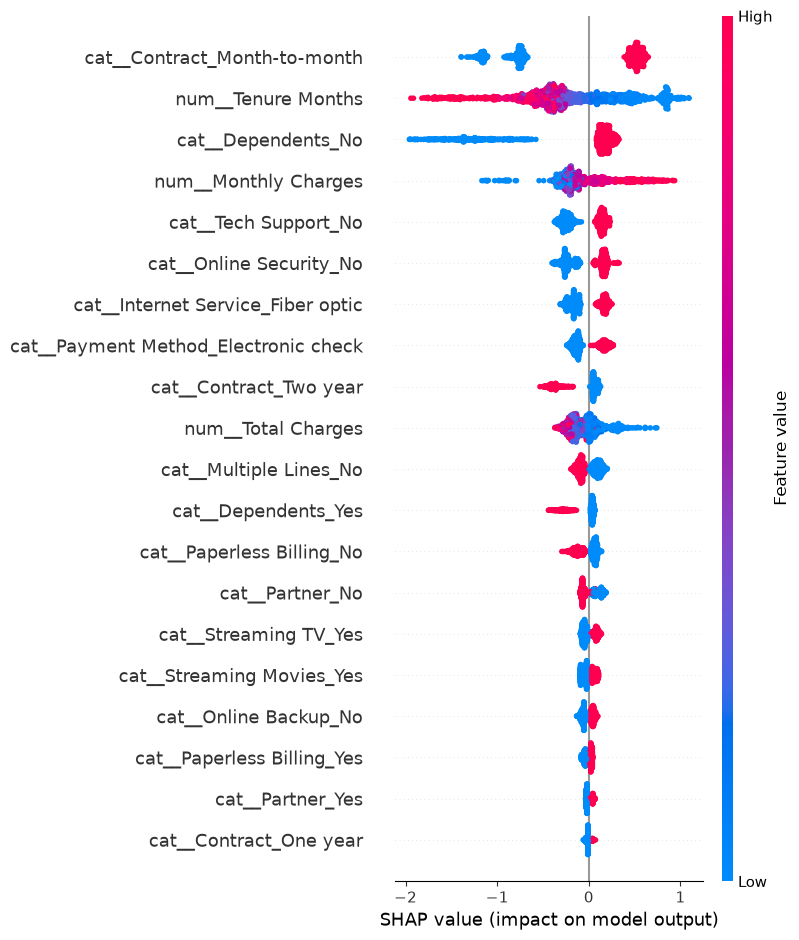

In [100]:
shap.summary_plot(
    shap_values,
    X_test_processed_xgb,
    feature_names=xgb_preprocessor.get_feature_names_out()
)

##### How to read it
- Right of 0 → pushes prediction toward churn
- Left of 0 → pushes prediction away from churn
- 🔴 Red → high feature value / category present (1)
- 🔵 Blue → low feature value / category absent (0)
- Features are ordered from most important at the top to least important at the bottom.

Also, the x-axis says SHAP value (impact on model output). These are contributions to the model's output, not direct percentage-point changes in churn probability.

| Finding                 | EDA                 | SHAP                               |
| ----------------------- | ------------------- | ---------------------------------- |
| Month-to-month contract | High churn          | Strong positive churn contribution |
| Short tenure            | Higher churn        | Strong positive contribution       |
| No dependents           | Higher churn        | Positive contribution              |
| Higher monthly charges  | Higher-risk pattern | Positive contribution              |
| Fiber optic             | High churn          | Positive contribution              |
| No online security      | High churn          | Positive contribution              |
| No tech support         | High churn          | Positive contribution              |
| Electronic check        | High churn          | Positive contribution              |
| Two-year contract       | Low churn           | Negative contribution              |


#### Individual Customer Explanation

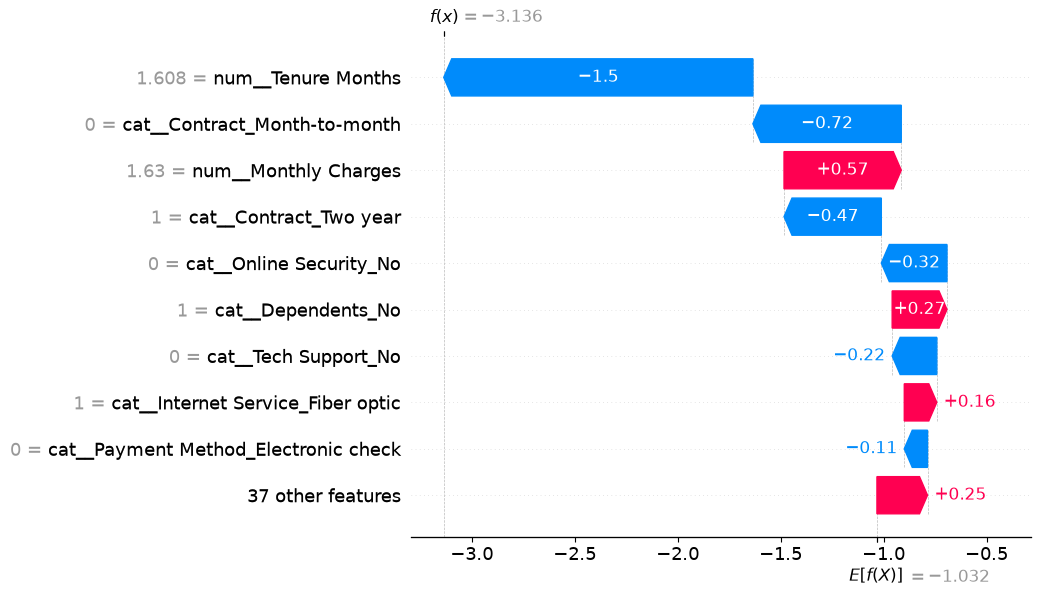

In [101]:
customer_index = 0

customer_shap = shap_values[customer_index]

shap.plots.waterfall(
    shap.Explanation(
        values=customer_shap,
        base_values=explainer.expected_value,
        data=X_test_processed_xgb[customer_index],
        feature_names=xgb_preprocessor.get_feature_names_out()
    )
)

We can summarize the customer's profile like this:

Factors reducing predicted churn

- High tenure → very strong reduction
- Not month-to-month → strong reduction
- Two-year contract → strong reduction
- Has online security → reduction
- Has tech support → reduction

Factors increasing predicted churn

- High monthly charges → moderate increase
- No dependents → moderate increase
- Fiber optic → small increase

The negative contributions clearly outweigh the positive ones.

View the actual customer's information

In [102]:
customer_profile = X_test.iloc[customer_index]

print(customer_profile)

Gender                                  Male
Senior Citizen                            No
Partner                                  Yes
Dependents                                No
Tenure Months                             72
Phone Service                            Yes
Multiple Lines                           Yes
Internet Service                 Fiber optic
Online Security                          Yes
Online Backup                            Yes
Device Protection                        Yes
Tech Support                             Yes
Streaming TV                             Yes
Streaming Movies                         Yes
Contract                            Two year
Paperless Billing                        Yes
Payment Method       Credit card (automatic)
Monthly Charges                       114.05
Total Charges                         8468.2
Name: 2196, dtype: object


In [103]:
customer_probability = xgb_final.predict_proba(X_test.iloc[[customer_index]])[0, 1]

print(f"Predicted churn probability: {customer_probability:.2%}")

Predicted churn probability: 4.16%


#### Business interpretation

The customer has some characteristics associated with higher predicted churn risk — particularly high monthly charges, fiber-optic service, and having no dependents.

However, the model's strongest signals point in the opposite direction:

72 months of tenure and a two-year contract substantially reduce the predicted churn risk, with online security and tech support providing additional downward contributions.

That's why the final predicted probability is only 4.05%.

## 9. Threshold Tuning

### 9.1. Random Forest

In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
 
y_train_bin = (y_train == "Yes").astype(int)
 
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
rf_oof_proba = cross_val_predict(
    best_rf_model, X_train, y_train_bin,
    cv=skf, method="predict_proba", n_jobs=-1
)[:, 1]

#### Best threshold using those OOF predictions

Best threshold: 0.56  (OOF F1 = 0.6467)
Plateau (within 0.01 F1 of best): 0.42 to 0.62
Grid edges: 0.20 to 0.80


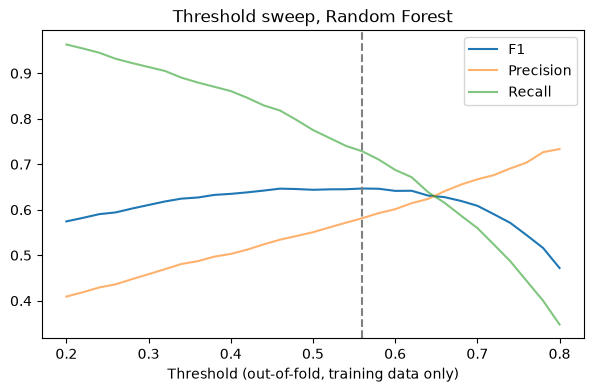

,Threshold,Precision,Recall,F1
0,0.20,0.4092,0.9632,0.5744
1,0.22,0.4187,0.9545,0.5821
2,0.24,0.4292,0.9452,0.5903
3,0.26,0.4361,0.9318,0.5942
4,0.28,0.4476,0.9224,0.6027
5,0.30,0.4584,0.9137,0.6105
6,0.32,0.4695,0.9050,0.6182
7,0.34,0.4809,0.8903,0.6244
8,0.36,0.4870,0.8796,0.6269
9,0.38,0.4969,0.8702,0.6326


In [ ]:
thresholds = np.arange(0.20, 0.81, 0.02)
 
rows = []
for t in thresholds:
    pred = (rf_oof_proba >= t).astype(int)
    rows.append({
        "Threshold": round(t, 2),
        "Precision": precision_score(y_train_bin, pred, zero_division=0),
        "Recall": recall_score(y_train_bin, pred),
        "F1": f1_score(y_train_bin, pred),
    })
threshold_df = pd.DataFrame(rows)
 
best_row = threshold_df.loc[threshold_df["F1"].idxmax()]
best_threshold = float(best_row["Threshold"])
best_oof_f1 = float(best_row["F1"])

plateau = threshold_df[threshold_df["F1"] >= best_oof_f1 - 0.01]["Threshold"]
 
print(f"Best threshold: {best_threshold:.2f}  (OOF F1 = {best_oof_f1:.4f})")
print(f"Plateau (within 0.01 F1 of best): {plateau.min():.2f} to {plateau.max():.2f}")
print(f"Grid edges: {thresholds.min():.2f} to {thresholds.max():.2f}")
if best_threshold in (round(thresholds.min(), 2), round(thresholds.max(), 2)):
    print("WARNING: best threshold is at the edge of the grid, so widen it further")
 
plt.figure(figsize=(7, 4))
plt.plot(threshold_df["Threshold"], threshold_df["F1"], label="F1")
plt.plot(threshold_df["Threshold"], threshold_df["Precision"], label="Precision", alpha=0.6)
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], label="Recall", alpha=0.6)
plt.axvline(best_threshold, linestyle="--", color="grey")
plt.xlabel("Threshold (out-of-fold, training data only)")
plt.legend()
plt.title("Threshold sweep, Random Forest")
plt.show()
 
threshold_df.round(4)

#### Highest OOF F1

In [106]:
selected_threshold = best_threshold
print("Selected threshold:", selected_threshold)

Selected threshold: 0.56


#### Final test-set evaluation

In [107]:
y_test_proba_rf = best_rf_model.predict_proba(X_test_no_cltv)[:, 1]

y_test_pred_rf_threshold = np.where(
    y_test_proba_rf >= selected_threshold,
    "Yes",
    "No"
)

#### Final test performance

In [108]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

test_accuracy = accuracy_score(y_test, y_test_pred_rf_threshold)

test_precision = precision_score(
    y_test,
    y_test_pred_rf_threshold,
    pos_label="Yes"
)

test_recall = recall_score(
    y_test,
    y_test_pred_rf_threshold,
    pos_label="Yes"
)

test_f1 = f1_score(
    y_test,
    y_test_pred_rf_threshold,
    pos_label="Yes"
)

test_cm = confusion_matrix(
    y_test,
    y_test_pred_rf_threshold,
    labels=["No", "Yes"]
)

print("Final Test Accuracy:", test_accuracy)
print("Final Test Precision:", test_precision)
print("Final Test Recall:", test_recall)
print("Final Test F1:", test_f1)

print("\nConfusion Matrix:")
print(test_cm)

Final Test Accuracy: 0.772888573456352
Final Test Precision: 0.55625
Final Test Recall: 0.713903743315508
Final Test F1: 0.6252927400468384

Confusion Matrix:
[[822 213]
 [107 267]]


#### Bootstrap the Random Forest F1

In [109]:
from sklearn.utils import resample

bootstrap_f1 = []

for i in range(2000):
    y_true_sample, y_pred_sample = resample(
        y_test,
        y_test_pred_rf_threshold,
        replace=True,
        random_state=i
    )

    f1 = f1_score(
        y_true_sample,
        y_pred_sample,
        pos_label="Yes"
    )

    bootstrap_f1.append(f1)

lower = np.percentile(bootstrap_f1, 2.5)
upper = np.percentile(bootstrap_f1, 97.5)

print("Test F1:", test_f1)
print("95% Bootstrap CI:", (lower, upper))

Test F1: 0.6252927400468384
95% Bootstrap CI: (np.float64(0.586977948027746), np.float64(0.6611594216793542))


Using 5-fold out-of-fold predictions on the training set only, F1 peaked at a threshold of 0.56 (OOF F1 = 0.647). F1 stayed within 0.01 of this value for thresholds from 0.42 to 0.62, so the choice is not sensitive within that range. On the held-out test set, the model achieved precision 0.556, recall 0.714 and F1 0.625 (95% bootstrap CI: 0.587 to 0.661). The test set was used once, after the threshold was fixed.

### 9.2. Comparing Random Forest vs XGBoost

In [110]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

y_train_bin = (y_train == "Yes").astype(int)
y_test_bin = (y_test == "Yes").astype(int).values

# Take the tuned XGBoost model from the last pipeline step (works whatever the step is named)
xgb_model = clone(grid_xgb.best_estimator_.steps[-1][1])

xgb_no_cltv = Pipeline([
    ("preprocessor", clone(preprocessor_no_cltv)),
    ("model", xgb_model),
])

xgb_oof_proba = cross_val_predict(
    xgb_no_cltv, X_train, y_train_bin,
    cv=skf, method="predict_proba", n_jobs=-1
)[:, 1]

#### Bootstrap the RF vs XGBoost difference

In [111]:
def sweep(y, p, grid):
    rows = []
    for t in grid:
        pred = (p >= t).astype(int)
        rows.append({
            "Threshold": round(t, 2),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred),
        })
    return pd.DataFrame(rows)


xgb_threshold_df = sweep(y_train_bin, xgb_oof_proba, thresholds)
xgb_best_row = xgb_threshold_df.loc[xgb_threshold_df["F1"].idxmax()]
xgb_threshold = float(xgb_best_row["Threshold"])
xgb_plateau = xgb_threshold_df[
    xgb_threshold_df["F1"] >= xgb_best_row["F1"] - 0.01]["Threshold"]

print(f"XGBoost best threshold: {xgb_threshold:.2f} (OOF F1 = {xgb_best_row['F1']:.4f})")
print(f"Plateau (within 0.01 F1 of best): {xgb_plateau.min():.2f} to {xgb_plateau.max():.2f}")
if xgb_threshold in (round(thresholds.min(), 2), round(thresholds.max(), 2)):
    print("WARNING: best threshold is at the edge of the grid, so widen it further")

# Training-side evidence (out-of-fold) for both models
print("\nOut-of-fold probability metrics (training data):")
print(f"RF : ROC-AUC {roc_auc_score(y_train_bin, rf_oof_proba):.4f} | "
      f"PR-AUC {average_precision_score(y_train_bin, rf_oof_proba):.4f}")
print(f"XGB: ROC-AUC {roc_auc_score(y_train_bin, xgb_oof_proba):.4f} | "
      f"PR-AUC {average_precision_score(y_train_bin, xgb_oof_proba):.4f}")

XGBoost best threshold: 0.36 (OOF F1 = 0.6553)
Plateau (within 0.01 F1 of best): 0.30 to 0.42

Out-of-fold probability metrics (training data):
RF : ROC-AUC 0.8590 | PR-AUC 0.6714
XGB: ROC-AUC 0.8637 | PR-AUC 0.6875


In [112]:
xgb_final = clone(xgb_no_cltv).fit(X_train, y_train_bin)

# Make sure CLTV is really out of both models
for label, model in [("RF", best_rf_model), ("XGB", xgb_final)]:
    names = model.named_steps["preprocessor"].get_feature_names_out()
    assert not any("CLTV" in n for n in names), f"{label} still uses CLTV"
print("Confirmed: neither model uses CLTV")

p_rf = best_rf_model.predict_proba(X_test)[:, 1]
p_xgb = xgb_final.predict_proba(X_test)[:, 1]

results = {
    "Random Forest": (p_rf, selected_threshold),
    "XGBoost": (p_xgb, xgb_threshold),
}

rows = []
for name, (p, t) in results.items():
    pred = (p >= t).astype(int)
    rows.append({
        "Model": name,
        "Threshold": round(t, 2),
        "Precision": precision_score(y_test_bin, pred),
        "Recall": recall_score(y_test_bin, pred),
        "F1": f1_score(y_test_bin, pred),
        "ROC-AUC": roc_auc_score(y_test_bin, p),
        "PR-AUC": average_precision_score(y_test_bin, p),
    })
pd.DataFrame(rows).round(4)

Confirmed: neither model uses CLTV


,Model,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.56,0.5562,0.7139,0.6253,0.8490,0.6607
1,XGBoost,0.36,0.5736,0.7193,0.6382,0.8549,0.6713


In [113]:
pred_rf = (p_rf >= selected_threshold).astype(int)
pred_xgb = (p_xgb >= xgb_threshold).astype(int)

rng = np.random.default_rng(42)
n = len(y_test_bin)
diffs = {"PR-AUC": [], "ROC-AUC": [], "F1 @ own threshold": []}

for _ in range(2000):
    idx = rng.integers(0, n, n)
    y = y_test_bin[idx]
    diffs["PR-AUC"].append(
        average_precision_score(y, p_rf[idx]) - average_precision_score(y, p_xgb[idx]))
    diffs["ROC-AUC"].append(
        roc_auc_score(y, p_rf[idx]) - roc_auc_score(y, p_xgb[idx]))
    diffs["F1 @ own threshold"].append(
        f1_score(y, pred_rf[idx]) - f1_score(y, pred_xgb[idx]))

for name, vals in diffs.items():
    lo, hi = np.percentile(vals, [2.5, 97.5])
    verdict = "CI includes 0" if lo < 0 < hi else "CI excludes 0"
    print(f"{name}: RF - XGB = {np.mean(vals):+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}] ({verdict})")


PR-AUC: RF - XGB = -0.0107, 95% CI [-0.0247, +0.0030] (CI includes 0)
ROC-AUC: RF - XGB = -0.0060, 95% CI [-0.0115, -0.0003] (CI excludes 0)
F1 @ own threshold: RF - XGB = -0.0129, 95% CI [-0.0315, +0.0062] (CI includes 0)


Both models used identical preprocessing (CLTV excluded) and thresholds chosen on out-of-fold predictions (RF 0.56, XGBoost 0.36). XGBoost scored slightly higher on all test metrics (F1 0.638 vs 0.625; PR-AUC 0.671 vs 0.661; ROC-AUC 0.855 vs 0.849). Paired bootstrap differences (RF − XGBoost) were −0.011 for PR-AUC (95% CI −0.025 to +0.003) and −0.013 for F1 (−0.032 to +0.006), both consistent with zero. The ROC-AUC difference (−0.006, CI −0.0115 to −0.0003) was detectable but practically negligible. The thresholds differ because the models output probabilities on different scales. We treat the models as equivalent in predictive performance and use Random Forest for interpretation and segmentation.

## 10. Customer Risk Segmentation

#### Step 1

In [114]:
test_churn_probability = best_rf_model.predict_proba(X_test_no_cltv)[:, 1]

print(test_churn_probability[:10])

[0.07473399 0.83284083 0.16410154 0.57893709 0.07137029 0.77824112
 0.63378471 0.20592541 0.00315805 0.62255428]


#### Step 2 — Create risk categories

Probability bands:

| Probability | Risk   |
| ----------: | ------ |
|     `< 30%` | Low    |
|    `30–60%` | Medium |
|     `≥ 60%` | High   |

These are our analytical categories, not universally established clinical/business thresholds. Later, we can change them based on the retention team's costs and objectives.

In [115]:
risk_category = np.where(
    test_churn_probability < 0.30,
    "Low",
    np.where(
        test_churn_probability < 0.60,
        "Medium",
        "High"
    )
)

print(risk_category[:10])

['Low' 'High' 'Low' 'Medium' 'Low' 'High' 'High' 'Low' 'Low' 'High']


#### Step 3 — Add risk and probability to the customer data

In [116]:
risk_df = X_test_no_cltv.copy()

risk_df["Churn Probability"] = test_churn_probability
risk_df["Risk Category"] = risk_category

print(risk_df.head())

      Gender Senior Citizen Partner Dependents  Tenure Months Phone Service  \
2196    Male             No     Yes         No             72           Yes   
3549  Female            Yes      No         No              8           Yes   
3515  Female             No     Yes         No             41           Yes   
5162    Male             No     Yes         No             18           Yes   
4642  Female             No     Yes         No             72           Yes   

     Multiple Lines Internet Service Online Security Online Backup  ...  \
2196            Yes      Fiber optic             Yes           Yes  ...   
3549            Yes      Fiber optic              No            No  ...   
3515            Yes              DSL             Yes           Yes  ...   
5162             No      Fiber optic              No            No  ...   
4642            Yes              DSL             Yes           Yes  ...   

     Tech Support Streaming TV Streaming Movies        Contract  \
2196   

#### Step 4 — Count the customers in each risk group

In [117]:
risk_summary = (
    risk_df["Risk Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename_axis("Risk Category")
    .reset_index(name="Customer Count")
)

risk_summary["Percentage"] = (
    risk_summary["Customer Count"] / len(risk_df) * 100
).round(2)

print(risk_summary)

  Risk Category  Customer Count  Percentage
0           Low             662       46.98
1        Medium             310       22.00
2          High             437       31.01


#### Step 5 — Visualize the risk distribution

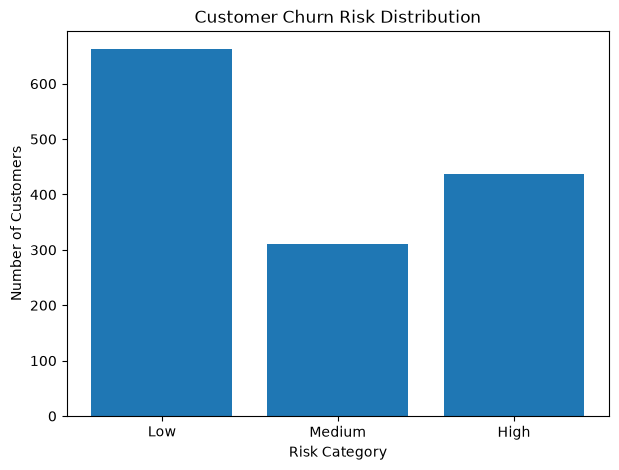

In [118]:
import matplotlib.pyplot as plt

risk_counts = risk_df["Risk Category"].value_counts()

risk_counts = risk_counts.reindex(["Low", "Medium", "High"])

plt.figure(figsize=(7, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Risk Distribution")

plt.show()

#### Step 6 — Analyze High-Risk Customers

In [119]:
contract_risk = (
    risk_df
    .groupby("Contract")["Churn Probability"]
    .mean()
    .sort_values(ascending=False)
)

print(contract_risk)

Contract
Month-to-month    0.594139
One year          0.199516
Two year          0.082884
Name: Churn Probability, dtype: float64


Visualize this

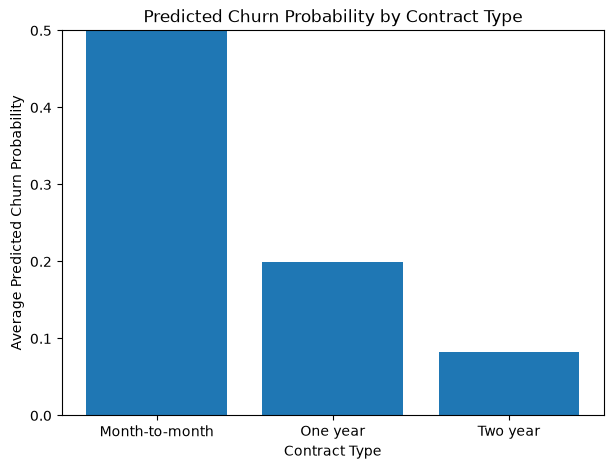

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    contract_risk.index,
    contract_risk.values
)

plt.xlabel("Contract Type")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Contract Type")

plt.ylim(0, 0.5)

plt.show()

#### Step 7 — Analyze churn risk by Tenure

In [121]:
risk_df["Tenure Group"] = pd.cut(
    risk_df["Tenure Months"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-36 months",
        "37-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

tenure_risk = (
    risk_df
    .groupby("Tenure Group", observed=True)["Churn Probability"]
    .mean()
)

print(tenure_risk)

Tenure Group
0-12 months     0.609090
13-24 months    0.464812
25-36 months    0.349116
37-48 months    0.289079
49-60 months    0.245818
61-72 months    0.135152
Name: Churn Probability, dtype: float64


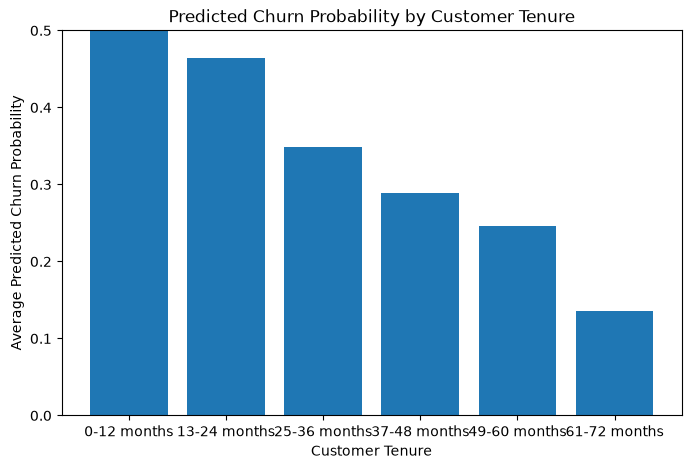

In [122]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    tenure_risk.index,
    tenure_risk.values
)

plt.xlabel("Customer Tenure")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Customer Tenure")

plt.ylim(0, 0.5)

plt.show()

#### Step 8 — Analyze churn risk by Internet Service

In [123]:
internet_risk = (
    risk_df
    .groupby("Internet Service")["Churn Probability"]
    .mean()
    .sort_values(ascending=False)
)

print(internet_risk)

Internet Service
Fiber optic    0.576076
DSL            0.313709
No             0.134626
Name: Churn Probability, dtype: float64


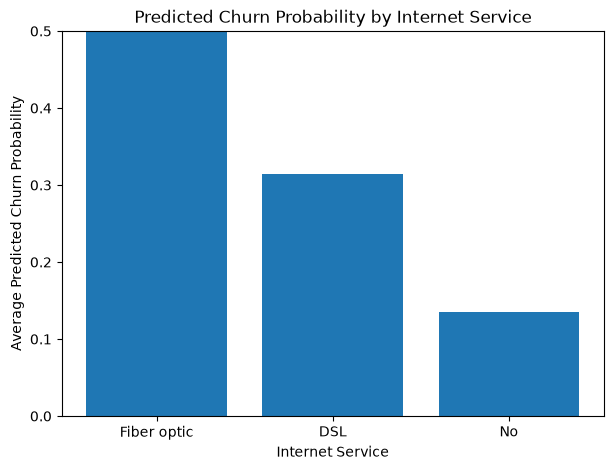

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    internet_risk.index,
    internet_risk.values
)

plt.xlabel("Internet Service")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Internet Service")

plt.ylim(0, 0.5)

plt.show()

#### Step 9 — Analyze churn risk by Payment Method

In [125]:
payment_risk = (
    risk_df
    .groupby("Payment Method")["Churn Probability"]
    .mean()
    .sort_values(ascending=False)
)

print(payment_risk)

Payment Method
Electronic check             0.593415
Mailed check                 0.307867
Bank transfer (automatic)    0.275095
Credit card (automatic)      0.267965
Name: Churn Probability, dtype: float64


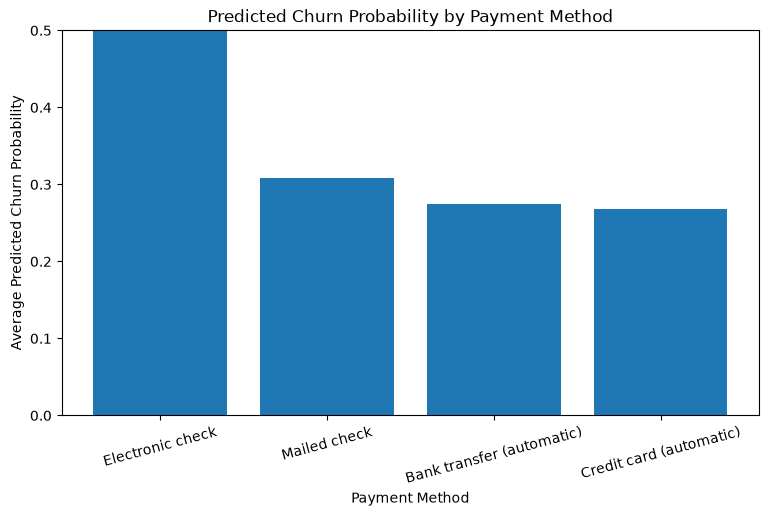

In [126]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    payment_risk.index,
    payment_risk.values
)

plt.xlabel("Payment Method")
plt.ylabel("Average Predicted Churn Probability")
plt.title("Predicted Churn Probability by Payment Method")

plt.ylim(0, 0.5)

plt.xticks(rotation=15)

plt.show()

**Conclusion**

Using Random Forest probabilities and analytical bands (<30%, 30–60%, ≥60%), 47.0% of test customers were classified as low risk, 22.0% as medium and 31.0% as high. These bands depend on the model’s probability scale, and calibration should be checked before they are used operationally.

## 11. Final Business Insights

The updated churn-prediction workflow excludes CLTV as a predictor and handles missing values in `Total Charges` through median imputation within the preprocessing pipeline. The following insights describe customer segments associated with elevated predicted churn risk. These relationships are observational and should not be interpreted as proof of causation.

### 1. Contract Type

**Month-to-month customers**
- Mean predicted churn probability: 42.84%
- Observed churn rate: 42.71%

Month-to-month customers show a substantially higher churn rate than customers on longer-term contracts.

**Business interpretation:** This segment may benefit from further investigation into pricing, contract flexibility, customer commitment, and retention offers. The analysis does not establish that contract type alone causes churn.

### 2. Customer Tenure

**Customers with 0–12 months of tenure**
- Mean predicted churn probability: 46.50%

**Customers with 61–72 months of tenure**
- Mean predicted churn probability: 6.55%

The results indicate a strong association between shorter tenure and higher churn risk.

**Business interpretation:** Early-tenure customers could be a priority for onboarding, customer engagement, and early retention initiatives. Monitoring customer experience during the first year may help identify opportunities to improve retention.

### 3. Internet Service Type

**Fiber optic**
- Mean predicted churn probability: 42.05%

**DSL**
- Mean predicted churn probability: 19.17%

**No internet service**
- Mean predicted churn probability: 7.43%

Fiber optic customers have a higher Mean predicted churn probability than the other groups in this analysis.

**Business interpretation:** Further investigation could examine pricing, service quality, customer expectations, and competitive alternatives to understand the differences between these segments. The observed pattern alone does not identify the underlying reason for churn.

### 4. Payment Method

**Electronic check**
- Mean predicted churn probability: 44.74%

**Mailed check**
- Mean predicted churn probability: 19.31%

**Credit card automatic payment**
- Mean predicted churn probability: 16.39%

**Bank transfer automatic payment**
- Mean predicted churn probability: 16.01%

Customers using electronic checks show a substantially higher churn rate than customers using automatic payment methods.

**Business interpretation:** This segment warrants further investigation into payment preferences, billing experience, and customer engagement. Any retention intervention should be based on additional evidence rather than assuming that the payment method itself causes churn.

### Overall Conclusion

The analysis highlights four customer segments worth investigating for retention opportunities: month-to-month customers, customers with shorter tenure, fiber optic customers, and electronic-check users.

These findings can help guide further analysis and targeted retention strategies. However, the percentages represent associations in the dataset, not guaranteed individual outcomes or causal effects. The final figures should be recalculated using the updated model and the same prediction method consistently across all four segments.

## 12. Business Recommendations

The churn-prediction model can help identify customer segments that may warrant closer attention. The recommendations below focus on investigating elevated predicted risk and developing retention strategies, rather than assuming that any single customer characteristic causes churn.

### 1. Prioritize Early-Tenure Customers

The model reports the following average predicted churn probabilities:

- **0–12 months:** 46.50%
- **61–72 months:** 6.55%

**Recommendation:** Develop an early-tenure retention program focused on the first year of the customer relationship. Potential initiatives include onboarding support, proactive service follow-ups, and early engagement campaigns.

**Rationale:** Customers with shorter tenure show substantially higher predicted churn risk in this analysis. Early engagement may provide an opportunity to identify and address customer concerns before they decide to leave.

### 2. Investigate Month-to-Month Customers

The reported average predicted churn probabilities by contract type are:

- **Month-to-month:** 42.84%
- **One-year contract:** 10.22%
- **Two-year contract:** 3.54%

**Recommendation:** Investigate the factors associated with higher predicted risk among month-to-month customers. Potential approaches include testing targeted retention offers, reviewing contract incentives, and examining service-related concerns.

**Rationale:** The differences suggest that month-to-month customers are an important segment to investigate. However, contract type may be associated with other customer characteristics, so the analysis does not establish that contract length itself causes churn.

### 3. Investigate the Fiber-Optic Customer Segment

The reported average predicted churn probabilities are:

- **Fiber optic:** 42.05%
- **DSL:** 19.17%

**Recommendation:** Examine the fiber-optic segment to understand what may be associated with its higher predicted risk. Areas for investigation include:

- Pricing and perceived value
- Service quality and reliability
- Customer expectations
- Technical issues
- Competitive alternatives
- Customer support experience

**Rationale:** The difference in predicted risk makes this segment worth further investigation. Additional customer feedback and service data would be needed to determine which factors, if any, explain the pattern.

### 4. Examine Electronic-Check Customers

Electronic-check customers have a reported average predicted churn probability of **44.74%**, compared with approximately **16–19%** for the other payment methods.

**Recommendation:** Investigate whether this segment differs in customer tenure, contract type, billing experience, or other characteristics. If payment-related issues are identified, the company could test alternative payment options or clearer billing communications.

**Rationale:** Electronic-check users represent a segment with elevated predicted risk in the supplied analysis. The payment method should not be assumed to cause churn without further evidence.

### 5. Use Predicted Risk to Prioritize Retention Efforts

In the supplied test-set analysis, 1,409 customers were assigned to three risk groups:

| Risk group | Customers | Percentage |
|---|---:|---:|
| Low | 662 | 46.98% |
| Medium | 310 | 22.00% |
| High | 437 | 31.01% |
| **Total** | **1,409** | **100%** |

**Recommendation:** Use predicted churn probabilities to help prioritize customer review and retention activities, subject to validation of the final model and risk thresholds.

| Risk group | Possible business approach |
|---|---|
| Low | Continue normal customer engagement and service monitoring |
| Medium | Monitor for changes and investigate potential concerns |
| High | Prioritize for customer review and suitable retention interventions |

The thresholds used to define these groups should be selected using validation data, the costs of retention activities, and the business impact of missed churners. Thresholds such as 30% and 60% should not be treated as universal standards.

### Overall Recommendation

Use the model as a decision-support tool to identify customer segments and individuals who may warrant attention. Validate the final predictions, investigate the factors associated with elevated risk, and test retention interventions before scaling them. The effectiveness of these interventions should be evaluated using measurable outcomes, such as subsequent churn rates and retention costs.

## 13. Project Limitations

### 1. Class Imbalance

Approximately 26.5% of customers in the dataset churned, while 73.5% did not. This class imbalance means that accuracy alone may not adequately describe the model's ability to identify customers who churn.

We addressed this challenge by:

- Using a stratified train-test split to preserve the target-class proportions.
- Using the F1 score for the churn (`Yes`) class during hyperparameter tuning.
- Allowing `class_weight="balanced"` for applicable models during tuning.
- Evaluating models using precision, recall, F1 score, ROC-AUC, and PR-AUC rather than relying on accuracy alone.

We did not apply SMOTE or undersampling. Therefore, the results reflect the models trained using the original class distribution, together with the selected preprocessing and model settings.

### 2. Association Does Not Imply Causation

The analysis identified customer segments associated with higher predicted churn risk, including:

- Month-to-month contract customers
- Customers with shorter tenure
- Fiber-optic customers
- Electronic-check users

However, the dataset is observational. These patterns do not establish that any of these characteristics directly causes churn. Other customer characteristics or circumstances may contribute to the observed differences.

For example, the statement *"Fiber-optic service causes customers to churn"* would not be supported by this analysis.

A more appropriate conclusion is: *"Fiber-optic customers show higher predicted churn risk in this dataset."*

Further investigation would be required to understand the factors associated with these patterns.

### 3. Reliance on a Single Dataset

The project uses 7,043 customer records from a single telecom dataset.

Consequently, we cannot assume that the model would achieve similar performance for:

- Another telecom company
- A different geographic market
- A different time period
- Future customer populations

The dataset may not represent the customer behaviour, service offerings, or business conditions of other organizations. External validation and evaluation on future data would be necessary before considering deployment.

### 4. Missing Business Variables

The dataset does not include several potentially useful real-world variables, such as:

- Customer complaints and satisfaction scores
- Network outages and service disruptions
- Number of customer-support interactions
- Competitor offers
- Pricing changes
- Detailed service usage
- Call and data consumption
- Customer engagement history

These variables could provide additional context about customer behaviour and potentially improve the usefulness of a production churn-prediction system. Their actual value would need to be assessed using suitable data and validation.

In addition, `CLTV` was excluded from the model features in the updated workflow. This keeps it out of the model's predictive inputs, although it does not eliminate all possible sources of bias or data leakage.

### 5. Classification Threshold Selection

Thresholds were selected using out-of-fold predictions on the training set, and the test set was used once for final evaluation. The F1-optimal threshold is not necessarily the business-optimal one. A company should weigh the cost of contacting customers who would not churn, the cost of missing churners, and the effectiveness of its retention offers. This analysis does not include a cost model. Hyperparameters were tuned with CLTV included and were not re-tuned after it was removed.

## 14. Conclusion

This project developed an end-to-end machine learning pipeline for analyzing and predicting customer churn using a telecom customer dataset containing 7,043 customer records. The analysis covered data cleaning, exploratory data analysis, feature preparation, stratified train-test splitting, categorical encoding, numerical feature scaling, model development, hyperparameter tuning, evaluation, model interpretation, and customer risk segmentation.

Seven classification algorithms were evaluated: Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest, AdaBoost, and XGBoost. Hyperparameters were optimized using 5-fold cross-validation, with the churn-class F1-score used as the primary tuning metric. Model performance was evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

In repeated cross-validation, the top four models (XGBoost, AdaBoost, Logistic Regression, Random Forest) were statistically hard to distinguish (PR-AUC 0.678 to 0.691). On the test set, AdaBoost, XGBoost and Random Forest led on PR-AUC (0.672, 0.671, 0.661). Random Forest was used for interpretation and segmentation, with a threshold of 0.56 selected on out-of-fold predictions, giving test precision 0.556, recall 0.714 and F1 0.625 (95% CI 0.587 to 0.661).

Random Forest probabilities were used to segment test customers into risk bands: 47.0% low, 22.0% medium and 31.0% high. These bands depend on the model’s probability scale, so calibration should be checked before operational use.

Model interpretation using feature importance, permutation importance, and SHAP identified factors such as contract type, tenure, dependents, internet service, monthly charges, total charges, online security, technical support, and payment method as important contributors to churn predictions. Risk segmentation further showed that customers with shorter tenure, month-to-month contracts, fiber-optic internet service, and electronic-check payment methods had higher average predicted churn probabilities.

The findings represent predictive associations rather than causal relationships. The analysis is based on a single dataset and does not include several potentially important business variables such as customer complaints, service outages, satisfaction, usage behavior, and competitor activity. Therefore, external or future-data validation would be required before deploying the model in a real-world environment.

Overall, the project demonstrates how machine learning can be applied to customer churn analysis to identify patterns, estimate individual customer risk, interpret important predictive factors, and support data-driven retention analysis.
